# Статистический анализ пользовательской активности и оценка A/B-теста интерфейса

**Автор:** Затула Денис Викторович  
**Дата:** 04.10.2026

Проект включает два независимых статистических исследования:

1. Проверка гипотезы о различии средней активности пользователей книжного сервиса в Санкт-Петербурге и Москве.
2. Аудит корректности и оценка результатов A/B-теста нового интерфейса интернет-магазина BitMotion Kit (`interface_eu_test`).

## Часть 1. Сравнение активности пользователей книжного сервиса (Санкт-Петербург vs Москва)

### Цели и задачи

**Цель:** статистически проверить гипотезу о том, что пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы.

**План работ:**

- Проверить данные на дубликаты пользователей между городами, пропуски и некорректные значения.
- Сравнить размеры выборок, описательные статистики и форму распределения часов активности.
- Провести односторонний двухвыборочный t-тест Уэлча (`alpha = 0,05`) и оценить минимально детектируемый эффект.
- Сформулировать выводы и рекомендации для продуктовой команды.

### Описание данных

Файл `../datasets/yandex_knigi_data.csv` содержит агрегированную активность пользователей по городам:

- `puid` — уникальный идентификатор пользователя;
- `city` — город пользователя (`Москва` или `Санкт-Петербург`);
- `hours` — суммарное количество часов чтения и прослушивания книг в приложении.

Для проведения теста формируется поле `test_group`: группа `A` — Санкт-Петербург, группа `B` — Москва.

### 1.1. Загрузка данных, очистка дубликатов и описательный анализ групп

In [1]:
# Загружаем библиотеки:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize
from math import ceil

In [2]:
# Загружаем данные в Датасет `df`
# index_col=0 — используем уже готовый индекс из исходного файла (сформирован на этапе SQL-выгрузки)
df = pd.read_csv('../datasets/yandex_knigi_data.csv', index_col = 0)
df

,city,puid,hours
0,Москва,9668,26.167776
1,Москва,16598,82.111217
2,Москва,80401,4.656906
3,Москва,140205,1.840556
4,Москва,248755,151.326434
...,...,...,...
8779,Санкт-Петербург,1130000028554332,4.107774
8780,Санкт-Петербург,1130000030307246,45.069222
8781,Санкт-Петербург,1130000038726322,0.211944
8782,Санкт-Петербург,1130000047892100,4.311841


In [3]:
# Выводим первые 5 строк Датафрейма:
df.head()

,city,puid,hours
0,Москва,9668,26.167776
1,Москва,16598,82.111217
2,Москва,80401,4.656906
3,Москва,140205,1.840556
4,Москва,248755,151.326434


In [4]:
# Проверяем информацию о Датафрейме:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   city    8784 non-null   str    
 1   puid    8784 non-null   int64  
 2   hours   8784 non-null   float64
dtypes: float64(1), int64(1), str(1)
memory usage: 206.0 KB


In [5]:
# Проверяем количество пропусков:
df.isna().sum()

city     0
puid     0
hours    0
dtype: int64

In [6]:
# Считаем количество строк до удаления дубликатов:
df_before_drop = df.shape[0]
print(f'Количество строк до удаления дубликатов: {df_before_drop}')

Количество строк до удаления дубликатов: 8784


In [7]:
# Смотрим количество дублирующих строк по пользователям:
# puid дублируется, если один и тот же пользователь встречается в данных сразу в двух городах
duplicated_rows = df.duplicated(subset='puid', keep=False).sum()
# Вычисляем долю дубликатов:
share_rows = duplicated_rows / df.shape[0] * 100
print(f'Количество дублирующих строк по одинаковым пользователям в разных городах: {duplicated_rows}')
print(f'Доля дублирующих строк: {share_rows.round(2)}%')

Количество дублирующих строк по одинаковым пользователям в разных городах: 488
Доля дублирующих строк: 5.56%


In [8]:
# Удаляем дубликаты: keep=False убирает ОБЕ копии пользователя, встретившегося в двух городах,
# чтобы один и тот же человек не оказался одновременно в группах A и B (независимость выборок)
df.drop_duplicates(subset='puid', keep=False, inplace=True)

/tmp/ipykernel_4410/489265762.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(subset='puid', keep=False, inplace=True)


In [9]:
# Считаем количество строк после удаления дубликатов:
df_after_drop = df.shape[0]
print(f'Количество строк после удаления дубликатов: {df_after_drop}')

Количество строк после удаления дубликатов: 8296


In [10]:
# Считаем количество удаленных строк в абсолютных и относительных значениях:
diff_df = abs(df_after_drop - df_before_drop)
share_diff_df = diff_df / df_before_drop * 100
print(f'Количество удалённых строк Датафрейма: {diff_df}')
print(f'Доля удалённых строк Датафрейма: {round(share_diff_df,2)}%')

Количество удалённых строк Датафрейма: 488
Доля удалённых строк Датафрейма: 5.56%


In [11]:
# Выведем статистику Датафрейма по часам:
df['hours'].describe(percentiles=[.05, .25, .5, .75, .95, .99])

count    8296.000000
mean       10.963892
std        37.753906
min         0.000022
5%          0.002080
25%         0.057493
50%         0.884214
75%         5.944675
95%        55.625093
99%       153.656226
max       978.764775
Name: hours, dtype: float64

In [12]:
# Проверяем наличие отрицательных и нулевых значений часов:
invalid_hours = df[df['hours'] <= 0]
print(f'Количество записей с hours <= 0: {invalid_hours.shape[0]}')
print(f'Доля таких записей: {invalid_hours.shape[0] / df.shape[0] * 100:.2f}%')

Количество записей с hours <= 0: 0
Доля таких записей: 0.00%


In [13]:
# Проверяем количество пользователей в разрезе городов:
df['city'].value_counts()

city
Москва             5990
Санкт-Петербург    2306
Name: count, dtype: int64

In [14]:
# Определяем тестовые группы: A — Санкт-Петербург (исследуемая группа по гипотезе),
# B — Москва (группа сравнения/референс)
df['test_group'] = df['city'].apply(lambda x: 'B' if x == 'Москва' else 'A')
users_per_group = df['test_group'].value_counts()
users_per_group

test_group
B    5990
A    2306
Name: count, dtype: int64

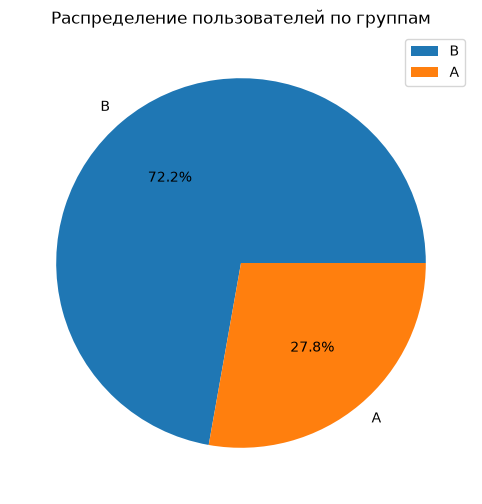

In [15]:
# Визуализируем соотношение размеров групп A и B (естественное распределение пользователей по городам, не случайный сплит)
plt.figure(figsize=(6, 6))
plt.pie(users_per_group.values, labels=users_per_group.index, autopct='%1.1f%%')
plt.title('Распределение пользователей по группам')
plt.legend()
plt.show()

In [16]:
# Сохраняем в отдельные Датафреймы пользователей из группы А и группы В:
df_a = df[df['test_group'] == 'A']
df_b = df[df['test_group'] == 'B']
# Выводим Датафреймы:
display(df_a)
display(df_b)

,city,puid,hours,test_group
6234,Санкт-Петербург,104923,60.353889,A
6235,Санкт-Петербург,146427,0.469559,A
6236,Санкт-Петербург,295646,1.258954,A
6237,Санкт-Петербург,601665,0.089076,A
6238,Санкт-Петербург,639360,0.334019,A
...,...,...,...,...
8778,Санкт-Петербург,1130000027468068,5.879444,A
8780,Санкт-Петербург,1130000030307246,45.069222,A
8781,Санкт-Петербург,1130000038726322,0.211944,A
8782,Санкт-Петербург,1130000047892100,4.311841,A


,city,puid,hours,test_group
0,Москва,9668,26.167776,B
1,Москва,16598,82.111217,B
2,Москва,80401,4.656906,B
3,Москва,140205,1.840556,B
4,Москва,248755,151.326434,B
...,...,...,...,...
6229,Москва,1130000059765086,0.003319,B
6230,Москва,1130000059999641,0.081234,B
6231,Москва,1130000060143349,0.024736,B
6232,Москва,1130000060647736,0.209018,B


In [17]:
# Выводим описательную статистику по Датафреймаму c группой A: 
display(df_a.describe())

,puid,hours
count,2.306000e+03,2306.000000
mean,5.391234e+12,11.264433
std,7.787547e+13,39.831755
min,1.049230e+05,0.000025
25%,3.594025e+08,0.060173
50%,9.265005e+08,0.875355
75%,1.542720e+09,6.138424
max,1.130000e+15,978.764775


In [18]:
# Выводим описательную статистику по Датафреймаму c группой B: 
display(df_b.describe())

,puid,hours
count,5.990000e+03,5990.000000
mean,1.037652e+13,10.848192
std,1.077902e+14,36.925622
min,9.668000e+03,0.000022
25%,3.140081e+08,0.057042
50%,8.757609e+08,0.888232
75%,1.517035e+09,5.933439
max,1.130000e+15,857.209373


In [19]:
# Сравнительная таблица описательных статистик по часам для групп A и B:
compare_stats = pd.DataFrame({
    'A (СПб)': df_a['hours'].describe(),
    'B (Москва)': df_b['hours'].describe()
})
compare_stats

,A (СПб),B (Москва)
count,2306.000000,5990.000000
mean,11.264433,10.848192
std,39.831755,36.925622
min,0.000025,0.000022
25%,0.060173,0.057042
50%,0.875355,0.888232
75%,6.138424,5.933439
max,978.764775,857.209373


In [20]:
# Считаем среднее по часам в разрезе групп:
print(f'Среднее по группе A:{round(df_a["hours"].mean(),2)}')
print(f'Среднее по группе В:{round(df_b["hours"].mean(),2)}')

Среднее по группе A:11.26
Среднее по группе В:10.85


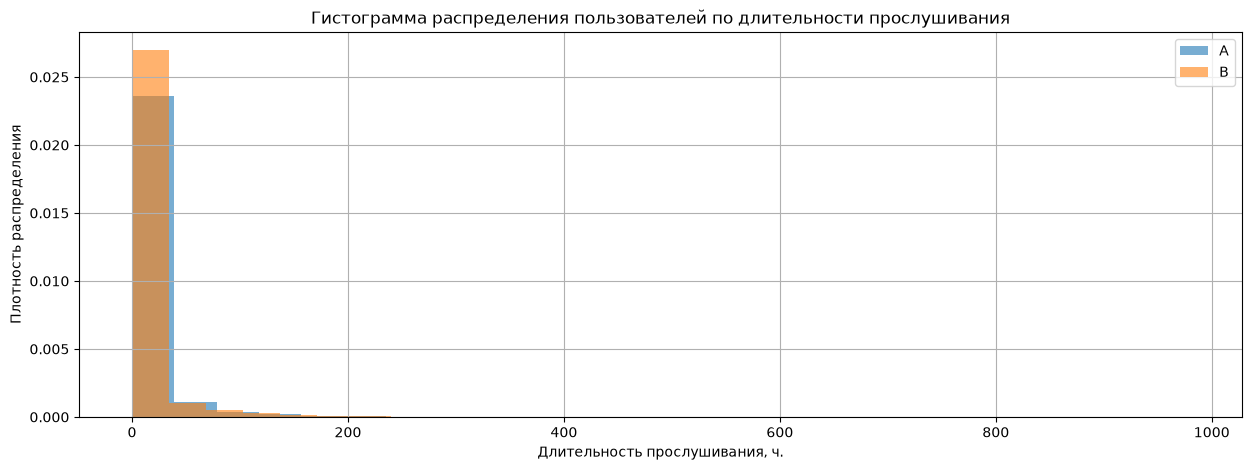

Средняя длительность прослушивания для пользователей из группы A: 11.26 ч, а для пользователей из группы B: 10.85 ч


In [21]:
# Гистограмма распределения пользователей по длительности прослушивания:
plt.figure(figsize=(15, 5))
# density=True — нормализуем гистограмму, т.к. группы разные по размеру (A=2306, B=5990)
# и сравнение "сырых" количеств искажало бы форму распределений
df_a['hours'].hist(bins=25, density=True, alpha=0.6, label='A')
df_b['hours'].hist(bins=25, density=True, alpha=0.6, label='B')
plt.xlabel('Длительность прослушивания, ч.')
plt.ylabel('Плотность распределения')
plt.title('Гистограмма распределения пользователей по длительности прослушивания')
plt.legend()
plt.show()

# Расчет и вывод на экран средней длительности прослушивания для пользователей групп A и B:
mean_hours_a = round(df_a['hours'].mean(),2)
mean_hours_b = round(df_b['hours'].mean(),2)
print(f'Средняя длительность прослушивания для пользователей из группы A: {mean_hours_a} ч, а для пользователей из группы B: {mean_hours_b} ч')

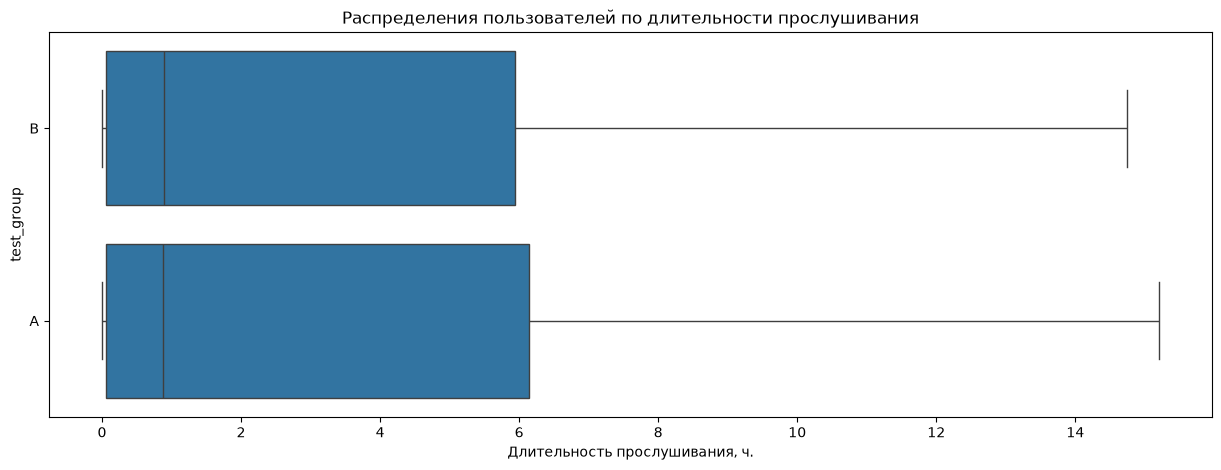

In [22]:
# Boxplot для визуального сравнения распределения часов по группам A и B (выбросы скрыты showfliers=False)
plt.figure(figsize=(15, 5))
sns.boxplot(data=df, x='hours', y='test_group', showfliers=False)
plt.xlabel('Длительность прослушивания, ч.')
plt.title('Распределения пользователей по длительности прослушивания')
plt.show()

In [23]:
# Считаем количество и долю выбросов по правилу IQR (1.5×IQR) для каждой группы:
for name, data in [('A (СПб)', df_a), ('B (Москва)', df_b)]:
    q1 = data['hours'].quantile(0.25)
    q3 = data['hours'].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = data[(data['hours'] < lower_bound) | (data['hours'] > upper_bound)]
    print(f'Группа {name}: границы IQR [{lower_bound:.2f}, {upper_bound:.2f}], '
          f'выбросов: {outliers.shape[0]} ({outliers.shape[0] / data.shape[0] * 100:.2f}%)')

Группа A (СПб): границы IQR [-9.06, 15.26], выбросов: 346 (15.00%)
Группа B (Москва): границы IQR [-8.76, 14.75], выбросов: 866 (14.46%)


### 1.2. Проверка статистической гипотезы (t-тест Уэлча)

- **H0:** средняя активность пользователей в Санкт-Петербурге не превышает среднюю активность в Москве ($\mu_{\text{СПб}} \leq \mu_{\text{Москва}}$).
- **H1:** средняя активность пользователей в Санкт-Петербурге статистически значимо выше ($\mu_{\text{СПб}} > \mu_{\text{Москва}}$).
- **Уровень значимости:** $\alpha = 0,05$.

In [24]:
# Задаём параметры:
alpha = 0.05           # Уровень значимости
beta = 0.2             # Ошибка второго рода
power = 1 - beta       # Мощность теста
# Проводим t-тест Уэлча (equal_var=False): не предполагаем равенство дисперсий групп заранее.
# alternative='greater' и df_a (СПб) передан первым — проверяем H1: μ_СПб > μ_Москва
res = st.ttest_ind(df_a['hours'], df_b['hours'], equal_var=False, alternative='greater')
res

TtestResult(statistic=np.float64(0.43499237928704976), pvalue=np.float64(0.3317959601847504), df=np.float64(3917.4816270130123))

In [25]:
# Разница выборок групп А и В:
diff_a_b = df_a["hours"].mean() - df_b["hours"].mean()
print(f'Среднее A = {df_a["hours"].mean():.2f} ч, среднее B = {df_b["hours"].mean():.2f} ч')
print(f'Разность = {diff_a_b:.2f} ч ({diff_a_b / df_b["hours"].mean():+.1%})')
print(f't = {res.statistic:.3f}, p-value = {res.pvalue:.6f}')
print('Решение:', 'отвергаем H0' if res.pvalue < alpha else 'нет оснований отвергнуть H0')

Среднее A = 11.26 ч, среднее B = 10.85 ч
Разность = 0.42 ч (+3.8%)
t = 0.435, p-value = 0.331796
Решение: нет оснований отвергнуть H0


In [26]:
# Дополнительная оценка чувствительности теста: оцениваем MDE и соответствующее
# ощутимое отклонение в часах при заданных alpha и мощности теста
# Рассчитываем отклонение в выборке по часам:
sp = (((len(df_a['hours']) - 1) * df_a['hours'].var() + (len(df_b['hours']) - 1) * df_b['hours'].var())
                                                / (len(df_a['hours']) + len(df_b['hours']) - 2)) ** 0.5

# Считаем MDE:
mde_d = TTestIndPower().solve_power(nobs1=len(df_a['hours']), 
                                    ratio=len(df_b['hours']) / len(df_a['hours']),
                                    alpha=alpha, power=power, alternative='larger')

print(f'Рассчитанный MDE : {(round(mde_d, 3))}')
print(f'Ощутимое отклонение: {round((sp * mde_d),2)} ч.')

Рассчитанный MDE : 0.061
Ощутимое отклонение: 2.3 ч.


### 1.3. Аналитическая записка по Части 1

Статистически значимых различий в активности пользователей Санкт-Петербурга и Москвы не выявлено.

- **Метод и параметры:** односторонний двухвыборочный t-тест Уэлча (`equal_var=False`, независимые выборки без предположения о равенстве дисперсий), уровень значимости $\alpha = 0,05$.
- **Результат теста:** `t = 0,435`, одностороннее `p-value = 0,332` ($> 0,05$). Оснований отвергнуть нулевую гипотезу нет.
- **Описательные оценки:** средняя активность в Санкт-Петербурге составила 11,26 ч, в Москве — 10,85 ч (разница +0,41 ч, или +3,8% относительно Москвы). Наблюдаемое расхождение не отличается от случайного колебания.
- **Возможные факторы:** меньший размер выборки Санкт-Петербурга (2 306 против 5 990 пользователей в Москве) и высокий разброс часов активности внутри обеих групп ограничивают мощность теста при оценке малых эффектов.
- **Рекомендация:** не принимать продуктовых решений на базе текущего различия между городами; при накоплении большего объема данных повторить проверку на расширенной выборке.

----

## Часть 2. Оценка результатов A/B-теста нового интерфейса BitMotion Kit

### Бизнес-контекст

Интернет-магазин геймифицированных товаров для здорового образа жизни BitMotion Kit разработал обновленную версию интерфейса сайта для упрощения пользовательского пути и роста конверсии. Для оценки эффективности обновления проведен A/B-эксперимент `interface_eu_test` с целевым ориентиром роста 7-дневной конверсии в покупку минимум на 3 п.п.

### Цели и план анализа

- Оценить целостность таблиц участников (`ab_test_participants.csv`) и событий (`ab_test_events.zip`).
- Проверить корректность сплитования `interface_eu_test`: исключить пересечения с конкурирующим тестом, оценить баланс размеров групп и распределения устройств.
- Выделить 7-дневный горизонт активности с момента регистрации и рассчитать конверсию в покупку для групп A и B.
- Проверить статистическую значимость роста конверсии (односторонний z-тест) и отдельно протестировать достижение целевого порога `+3 п.п.`.
- Сформировать рекомендацию по раскатке интерфейса.

### 2.1. Загрузка данных и оценка целостности

In [27]:
# Загружаем данные о участниках и событиях A/B-тестов (две таблицы: participants, events):
participants = pd.read_csv('../datasets/ab_test_participants.csv')
events = pd.read_csv('../datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [28]:
# Проверяем структуру и типы данных таблицы участников:
participants.info()

<class 'pandas.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   user_id  14525 non-null  str  
 1   group    14525 non-null  str  
 2   ab_test  14525 non-null  str  
 3   device   14525 non-null  str  
dtypes: str(4)
memory usage: 454.0 KB


In [29]:
# Проверяем структуру и типы данных таблицы событий:
events.info()

<class 'pandas.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  str           
 1   event_dt    787286 non-null  datetime64[us]
 2   event_name  787286 non-null  str           
 3   details     249022 non-null  str           
dtypes: datetime64[us](1), str(3)
memory usage: 24.0 MB


In [30]:
# Смотрим первые строки таблицы участников:
participants.head()

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


In [31]:
# Смотрим первые строки таблицы событий:
events.head()

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


In [32]:
# Цикл для 2 Датафреймов для поиска дубликатов, пропусков:
for name, t in [('participants', participants), ('events', events)]:
    print(name, t.shape)
    print('Типы данных')
    print(t.dtypes)
    print('Пропуски')
    print(t.isna().sum())
    print('Дубли')
    print('полных дублей:', t.duplicated().sum())
    print('\n')

participants (14525, 4)
Типы данных
user_id    str
group      str
ab_test    str
device     str
dtype: object
Пропуски
user_id    0
group      0
ab_test    0
device     0
dtype: int64
Дубли
полных дублей: 0


events (787286, 4)
Типы данных
user_id                  str
event_dt      datetime64[us]
event_name               str
details                  str
dtype: object
Пропуски
user_id            0
event_dt           0
event_name         0
details       538264
dtype: int64
Дубли


полных дублей: 36318




In [33]:
# Смотрим количество пользователей по типам тестов:
participants['ab_test'].value_counts()

ab_test
interface_eu_test          10850
recommender_system_test     3675
Name: count, dtype: int64

In [34]:
# Считаем количество уникальных юзеров в разрезе групп и АБ-теста:
participants.groupby(['ab_test', 'group'])['user_id'].nunique()

ab_test                  group
interface_eu_test        A        5383
                         B        5467
recommender_system_test  A        2747
                         B         928
Name: user_id, dtype: int64

In [35]:
# Проверяем события, которые есть в Датафрейме:
events['event_name'].value_counts()

event_name
login                                 248285
product_page                          195606
registration                          144183
purchase                              104836
product_cart                           94373
End of Black Friday Ads Campaign           1
Start of Christmas&New Year Promo          1
Start of CIS New Year Gift Lottery         1
Name: count, dtype: int64

In [36]:
# Периоды событий:
events['event_dt'].describe()

count                        787286
mean     2020-12-16 18:02:17.995430
min             2020-12-01 00:00:00
25%      2020-12-11 06:27:25.750000
50%      2020-12-16 14:15:16.500000
75%      2020-12-22 04:28:38.250000
max             2020-12-31 23:59:48
Name: event_dt, dtype: object

### 2.2. Аудит корректности проведения A/B-теста (`interface_eu_test`)

Выделяем участников целевого теста, исключаем пересечения с конкурирующим экспериментом и проверяем баланс групп A и B по численности и типам устройств.

In [37]:
# Фильтруем по А/В тесту interface_eu_test:
df_ab_test = participants[participants['ab_test'] == 'interface_eu_test'].copy()
# Количество пользователей теста:
df_count_before = df_ab_test.shape[0]
df_ab_test

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
2,001064FEAAB631A1,A,interface_eu_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac
5,002412F1EB3F6E38,B,interface_eu_test,Mac
6,002540BE89C930FB,B,interface_eu_test,Android
...,...,...,...,...
14519,FFE600EEC4BA7685,B,interface_eu_test,Android
14520,FFE7FC140521F5F6,A,interface_eu_test,PC
14521,FFEFC0E55C1CCD4F,A,interface_eu_test,PC
14523,FFF28D02B1EACBE1,B,interface_eu_test,PC


In [38]:
# Проверяем пересечение по тестам:
user_by_test = participants.groupby('user_id')['ab_test'].nunique()
display(user_by_test)
df_ab_test = df_ab_test[~df_ab_test['user_id'].isin(user_by_test[user_by_test > 1].index)]
df_ab_test

user_id
0002CE61FF2C4011    1
001064FEAAB631A1    2
0010A1C096941592    1
001E72F50D1C48FA    1
002412F1EB3F6E38    1
                   ..
FFE600EEC4BA7685    1
FFE7FC140521F5F6    1
FFEFC0E55C1CCD4F    1
FFF28D02B1EACBE1    2
FFF58BC33966EB51    1
Name: ab_test, Length: 13638, dtype: int64

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
4,001E72F50D1C48FA,A,interface_eu_test,Mac
5,002412F1EB3F6E38,B,interface_eu_test,Mac
6,002540BE89C930FB,B,interface_eu_test,Android
7,0031F1B5E9FBF708,A,interface_eu_test,Android
...,...,...,...,...
14518,FFE5B14BD55C1C5C,A,interface_eu_test,PC
14519,FFE600EEC4BA7685,B,interface_eu_test,Android
14520,FFE7FC140521F5F6,A,interface_eu_test,PC
14521,FFEFC0E55C1CCD4F,A,interface_eu_test,PC


In [39]:
# Считаем количество удалённых строк в абсолютном и относительном значениях:
diff_ab_test = df_count_before - df_ab_test.shape[0]
print(f'Количество удалённых строк: {diff_ab_test}')
print(f'Процент удаленных строк: {round(diff_ab_test / df_count_before * 100, 2)}%')

Количество удалённых строк: 887
Процент удаленных строк: 8.18%


In [40]:
# Выводим информацию по Датафрейму:
df_ab_test.info()

<class 'pandas.DataFrame'>
Index: 9963 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   user_id  9963 non-null   str  
 1   group    9963 non-null   str  
 2   ab_test  9963 non-null   str  
 3   device   9963 non-null   str  
dtypes: str(4)
memory usage: 389.2 KB


In [41]:
# Проверяем количество уникальных юзеров:
df_ab_test['user_id'].nunique()

9963

In [42]:
# Количество уникальных юзеров в разрезе групп А и В:
df_ab_test.groupby('group')['user_id'].nunique()

group
A    4952
B    5011
Name: user_id, dtype: int64

In [43]:
# Считаем вхождение пользователей в разные группы(пересечение):
user_per_group = df_ab_test.groupby('user_id')['group'].nunique()
groups_intersection = user_per_group[user_per_group > 1].index
print(f'Количество одинаковых пользователей в обеих группах : {groups_intersection.shape[0]}')

Количество одинаковых пользователей в обеих группах : 0


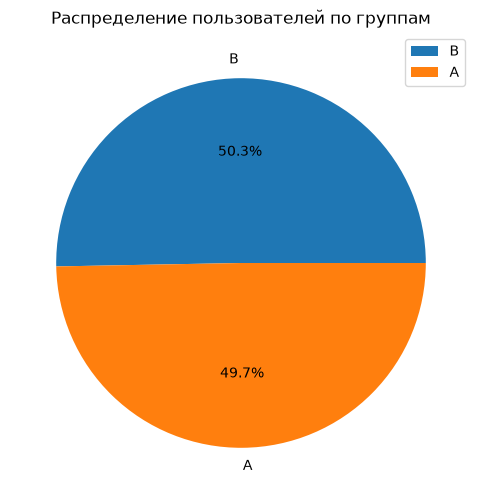

In [44]:
# Смотрим размеры групп:
# Визуализация различия групп А и В:
user_per_group = df_ab_test['group'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(user_per_group.values, labels=user_per_group.index, autopct='%1.1f%%')
plt.title('Распределение пользователей по группам')
plt.legend()
plt.show()

In [45]:
# Считаем количество юзеров для каждого типа устройства для пользователей из групп А и В:
device_dist = df_ab_test.groupby(['group', 'device'])['user_id'].nunique().unstack()
device_dist

device,Android,Mac,PC,iPhone
group,,,,
A,2264,515,1223,950
B,2218,511,1302,980


In [46]:
# Считаем долю для каждого типа устройства для пользователей из групп А и В:
device_dist_pct = device_dist.div(device_dist.sum(axis=1), axis=0) * 100
device_dist_pct

device,Android,Mac,PC,iPhone
group,,,,
A,45.718901,10.399838,24.697092,19.184168
B,44.262622,10.197565,25.982838,19.556975


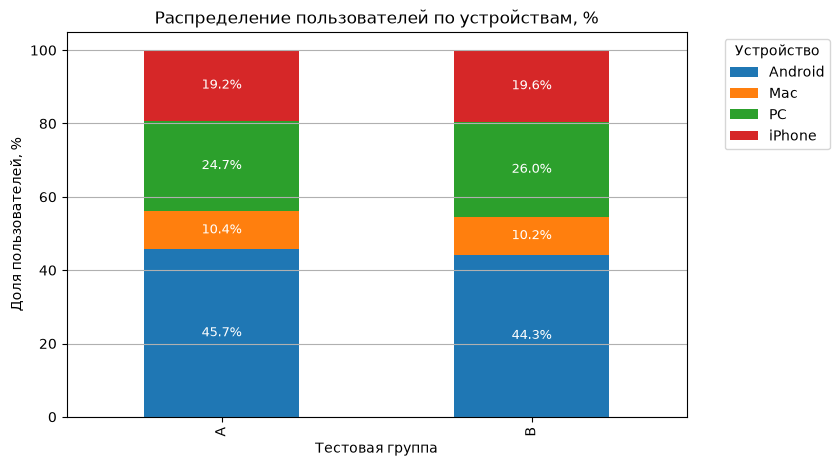

In [47]:
# Строим визуализацию распределения пользователей по устройствам:
ax = device_dist_pct.plot(kind='bar', stacked=True, figsize=(8, 5))
for container in ax.containers:
    for bar in container:
        height = bar.get_height()

        if height >= 3:  # не выводим текст для слишком маленьких долей
            x = bar.get_x() + bar.get_width() / 2
            y = bar.get_y() + height / 2

            ax.text(
                x,
                y,
                f'{height:.1f}%',
                ha='center',
                va='center',
                fontsize=9,
                color='white'
            )
plt.title('Распределение пользователей по устройствам, %')
plt.xlabel('Тестовая группа')
plt.ylabel('Доля пользователей, %')
plt.legend(title='Устройство', bbox_to_anchor=(1.05, 1))
plt.grid(axis='y')
plt.show()

Промежуточный вывод: Выборки A/B теста одинаковы

### 2.3. Фильтрация событий и расчет 7-дневного окна после регистрации

In [48]:
# Объединяем участников нужного теста с таблицей событий (inner join по user_id):
events_ab = df_ab_test.merge(events, how = 'inner', on = 'user_id')
events_ab.head(10)

,user_id,group,ab_test,device,event_dt,event_name,details
0,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:31,registration,-2.38
1,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:49,login,NaN
2,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:57,login,NaN
3,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:38:54,login,NaN
4,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-08 22:15:35,login,NaN
5,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-08 22:15:36,product_page,NaN
6,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-08 22:15:37,product_page,NaN
7,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-10 15:23:08,product_page,NaN
8,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-10 15:23:09,product_cart,NaN
9,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-15 12:50:07,product_cart,NaN


In [49]:
# Выводим информацию по объединённому Датафрейму:
events_ab.info()

<class 'pandas.DataFrame'>
RangeIndex: 73815 entries, 0 to 73814
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     73815 non-null  str           
 1   group       73815 non-null  str           
 2   ab_test     73815 non-null  str           
 3   device      73815 non-null  str           
 4   event_dt    73815 non-null  datetime64[us]
 5   event_name  73815 non-null  str           
 6   details     19450 non-null  str           
dtypes: datetime64[us](1), str(6)
memory usage: 3.9 MB


Рассчитываем лайфтайм каждого события относительно времени регистрации (`reg_dt`) и ограничиваем выборку первыми 7 днями.

In [50]:
# Фильтруем по событию 'регистрация':
reg = events_ab[events_ab['event_name'] == 'registration'].copy()
reg

,user_id,group,ab_test,device,event_dt,event_name,details
0,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:31,registration,-2.38
11,001E72F50D1C48FA,A,interface_eu_test,Mac,2020-12-17 15:44:05,registration,-3.61
18,002412F1EB3F6E38,B,interface_eu_test,Mac,2020-12-09 09:36:50,registration,-0.48
26,002540BE89C930FB,B,interface_eu_test,Android,2020-12-08 18:06:07,registration,-2.38
35,0031F1B5E9FBF708,A,interface_eu_test,Android,2020-12-14 00:47:10,registration,-2.26
...,...,...,...,...,...,...,...
73784,FFE5B14BD55C1C5C,A,interface_eu_test,PC,2020-12-19 06:27:24,registration,-0.45
73787,FFE600EEC4BA7685,B,interface_eu_test,Android,2020-12-13 21:43:31,registration,-2.26
73794,FFE7FC140521F5F6,A,interface_eu_test,PC,2020-12-23 09:10:16,registration,-3.43
73809,FFEFC0E55C1CCD4F,A,interface_eu_test,PC,2020-12-13 23:52:15,registration,0.0


In [51]:
# Проверяем уникальность юзеров по событию 'регистрация':
uniq_reg_count = reg.groupby('user_id')['event_name'].count()
print(f' Количество дублирующих регистраций по user_id: {uniq_reg_count[uniq_reg_count > 1].index.shape[0]}')

 Количество дублирующих регистраций по user_id: 0


In [52]:
# Переименовываем колонку дата и время события(event_dt) в дату регистрации(reg_dt):
reg.rename({'event_dt': 'reg_dt'}, inplace=True, axis=1)
reg

/tmp/ipykernel_4410/392911387.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  reg.rename({'event_dt': 'reg_dt'}, inplace=True, axis=1)


,user_id,group,ab_test,device,reg_dt,event_name,details
0,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:31,registration,-2.38
11,001E72F50D1C48FA,A,interface_eu_test,Mac,2020-12-17 15:44:05,registration,-3.61
18,002412F1EB3F6E38,B,interface_eu_test,Mac,2020-12-09 09:36:50,registration,-0.48
26,002540BE89C930FB,B,interface_eu_test,Android,2020-12-08 18:06:07,registration,-2.38
35,0031F1B5E9FBF708,A,interface_eu_test,Android,2020-12-14 00:47:10,registration,-2.26
...,...,...,...,...,...,...,...
73784,FFE5B14BD55C1C5C,A,interface_eu_test,PC,2020-12-19 06:27:24,registration,-0.45
73787,FFE600EEC4BA7685,B,interface_eu_test,Android,2020-12-13 21:43:31,registration,-2.26
73794,FFE7FC140521F5F6,A,interface_eu_test,PC,2020-12-23 09:10:16,registration,-3.43
73809,FFEFC0E55C1CCD4F,A,interface_eu_test,PC,2020-12-13 23:52:15,registration,0.0


In [53]:
# Объединяем Датафреймы:
events_ab = events_ab.merge(reg[['user_id','reg_dt']], how='left', on='user_id')
events_ab

,user_id,group,ab_test,device,event_dt,event_name,details,reg_dt
0,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:31,registration,-2.38,2020-12-07 04:37:31
1,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:49,login,NaN,2020-12-07 04:37:31
2,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:57,login,NaN,2020-12-07 04:37:31
3,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:38:54,login,NaN,2020-12-07 04:37:31
4,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-08 22:15:35,login,NaN,2020-12-07 04:37:31
...,...,...,...,...,...,...,...,...
73810,FFEFC0E55C1CCD4F,A,interface_eu_test,PC,2020-12-13 23:52:22,login,NaN,2020-12-13 23:52:15
73811,FFEFC0E55C1CCD4F,A,interface_eu_test,PC,2020-12-28 00:29:10,login,NaN,2020-12-13 23:52:15
73812,FFF58BC33966EB51,A,interface_eu_test,Android,2020-12-13 17:37:34,registration,-0.45,2020-12-13 17:37:34
73813,FFF58BC33966EB51,A,interface_eu_test,Android,2020-12-13 17:56:02,login,NaN,2020-12-13 17:37:34


In [54]:
# Посчитаем lifetime:
events_ab['lifetime'] = events_ab['event_dt'] - events_ab['reg_dt']
events_ab

,user_id,group,ab_test,device,event_dt,event_name,details,reg_dt,lifetime
0,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:31,registration,-2.38,2020-12-07 04:37:31,0 days 00:00:00
1,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:49,login,NaN,2020-12-07 04:37:31,0 days 00:00:18
2,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:57,login,NaN,2020-12-07 04:37:31,0 days 00:00:26
3,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:38:54,login,NaN,2020-12-07 04:37:31,0 days 00:01:23
4,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-08 22:15:35,login,NaN,2020-12-07 04:37:31,1 days 17:38:04
...,...,...,...,...,...,...,...,...,...
73810,FFEFC0E55C1CCD4F,A,interface_eu_test,PC,2020-12-13 23:52:22,login,NaN,2020-12-13 23:52:15,0 days 00:00:07
73811,FFEFC0E55C1CCD4F,A,interface_eu_test,PC,2020-12-28 00:29:10,login,NaN,2020-12-13 23:52:15,14 days 00:36:55
73812,FFF58BC33966EB51,A,interface_eu_test,Android,2020-12-13 17:37:34,registration,-0.45,2020-12-13 17:37:34,0 days 00:00:00
73813,FFF58BC33966EB51,A,interface_eu_test,Android,2020-12-13 17:56:02,login,NaN,2020-12-13 17:37:34,0 days 00:18:28


In [55]:
# Фильтруемся по событиям, которые произошли в теч 7 дней с начала регистрации:
events_ab = events_ab[(events_ab['lifetime'] >= pd.Timedelta(0)) & (events_ab['lifetime'] <= pd.Timedelta(days=7))]
print(f'Максимальный lifetime: {events_ab["lifetime"].max()}')
print(f'Минимальный lifetime: {events_ab["lifetime"].min()}')
print(f'Максимальный reg_dt: {events_ab["reg_dt"].max()}')

Максимальный lifetime: 6 days 23:58:10
Минимальный lifetime: 0 days 00:00:00
Максимальный reg_dt: 2020-12-24 21:57:10


In [56]:
# Проверим, есть ли какие-то события до того как юзер зарегистрировался:
events_ab[events_ab['lifetime'] < pd.Timedelta(0)]
print(f'Событий до регистрации: {events_ab[events_ab["lifetime"] < pd.Timedelta(0)].shape[0]}')

Событий до регистрации: 0


### 2.4. Оценка достаточности выборки и расчет конверсии по группам

Параметры оценки достаточности: базовая конверсия `30%`, абсолютный MDE `+3 п.п.`, мощность `80%`, уровень достоверности `95%` (`alpha = 0,05`).

In [57]:
# Оценим достаточность выборки для получения статистически значимых результатов A/B-теста:
# Задаём параметры:
alpha = 0.05           # Уровень значимости
beta = 0.2             # Ошибка второго рода
power = 1 - beta       # Мощность теста
p = 0.3                # Базовый уровень доли (текущая конверсия)
mde = 0.03             # Ожидаемый детектируемый эффект

# MDE = 3 п.п. — это АБСОЛЮТНЫЙ эффект по ТЗ (минимум на три процентных пункта).
# mde_relative выражаем через mde_absolute только для справки.
mde_absolute = mde                      # Абсолютный эффект в долях: 0.03 (3 п.п.)
p_target = p + mde_absolute             # Ожидаемая доля в тесте: 0.3 + 0.03 = 0.33
mde_relative = mde_absolute / p         # Относительный эквивалент MDE, для справки

effect_size = proportion_effectsize(p, p_target)

power_analysis = NormalIndPower()

sample_size = power_analysis.solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=1
)

# Округляем ВВЕРХ, а не отбрасываем дробную часть через int()
sample_size = ceil(sample_size)

print(f"Базовая доля: {p:.1%}")
print(f"Ожидаемая доля при абсолютном MDE {mde_absolute*100:.0f} п.п.: {p_target:.2%}")
print(f"Относительный эквивалент MDE: {mde_relative:.1%}")
print(f"Необходимый размер выборки для каждой группы: {sample_size}")

Базовая доля: 30.0%
Ожидаемая доля при абсолютном MDE 3 п.п.: 33.00%
Относительный эквивалент MDE: 10.0%
Необходимый размер выборки для каждой группы: 3762


In [58]:
# Фильтруем посетителей, которые совершили покупку:
purchase_events = events_ab[events_ab['event_name'] == 'purchase']
# Считаем количество уникальных посетителей, которые совершили покупку в разрезе групп:
users_purchase_by_group = purchase_events.groupby('group')['user_id'].nunique()
# Считаем общее количество пользователей:
total_users = events_ab.groupby('group')['user_id'].nunique()
# Объединяем `users_purchase_by_group` и `total_users` в один Датафрейм:
group_df = pd.DataFrame({'buyers': users_purchase_by_group, 'visitors': total_users})
group_df['conversion_rate'] = group_df['buyers'] / group_df['visitors']
group_df

,buyers,visitors,conversion_rate
group,,,
A,1377,4952,0.278069
B,1480,5011,0.295350


Предварительно: в тестовой группе B (новый интерфейс) доля зарегистрированных пользователей, совершивших покупку в течение 7 дней, выше, чем в контрольной группе A — 29.54% против 27.81% (разница +1.73 п.п.). Это пока только описательное наблюдение по собранным данным; является ли разница статистически значимой и достигнут ли заявленный порог +3 п.п., проверим в следующем разделе.

### 2.5. Статистическая проверка результатов A/B-теста

**Формулировка гипотез и метрик:**

- **H0:** 7-дневная конверсия зарегистрированных пользователей в покупателей в группе B не превышает конверсию в группе A ($p_B \leq p_A$).
- **H1:** 7-дневная конверсия в группе B статистически значимо выше ($p_B > p_A$).
- **Метрика эксперимента:** конверсия зарегистрированных пользователей в покупку в первые 7 дней (`conversion_rate`).
- **Барьерные метрики:** время отклика страниц, показатель отказов (churn rate).
- **Группы:** `A` — контрольная (базовый интерфейс), `B` — тестовая (новый интерфейс интернет-магазина).

In [59]:
# Проверяем условия применимости z-теста для долей (n*p >= 10 и n*(1-p) >= 10) для каждой группы:
for group in ['A', 'B']:
    n_group = group_df.loc[group, 'visitors']
    p_hat = group_df.loc[group, 'conversion_rate']
    print(f"Группа {group}: n*p = {n_group * p_hat:.1f}, n*(1-p) = {n_group * (1 - p_hat):.1f}")

Группа A: n*p = 1377.0, n*(1-p) = 3575.0
Группа B: n*p = 1480.0, n*(1-p) = 3531.0


In [60]:
# Проводим Z тест: B — первая группа, тестируем H1: p_B > p_A (как в гипотезе выше).
# alternative='larger' — одностороннее направление, т.к. интересует только рост конверсии
x = np.array([group_df.loc['B', 'buyers'], group_df.loc['A', 'buyers']])
n = np.array([group_df.loc['B', 'visitors'], group_df.loc['A', 'visitors']])
z, p_value = proportions_ztest(count=x, nobs=n, alternative='larger')
print(f"P-value: {p_value:.4f}")

P-value: 0.0283


In [61]:
# Доверительный интервал для разницы долей (B - A), чтобы оценить не только
# статистическую значимость, но и величину/точность эффекта относительно MDE
# alpha=0.10 для двустороннего ДИ соответствует одностороннему тесту с alpha=0.05
ci_low, ci_upp = confint_proportions_2indep(
    count1=group_df.loc['B', 'buyers'], nobs1=group_df.loc['B', 'visitors'],
    count2=group_df.loc['A', 'buyers'], nobs2=group_df.loc['A', 'visitors'],
    method='wald', alpha=0.10
)
diff = group_df.loc['B', 'conversion_rate'] - group_df.loc['A', 'conversion_rate']

# mde_absolute (3 п.п.) и mde_relative рассчитаны в разделе 2.1 — mde_absolute
# используется как плановый порог эффекта по ТЗ, mde_relative — для справки.
print(f"Точечная разница долей (B - A): {diff:.2%}")
print(f"90%-й доверительный интервал разницы долей (B - A): [{ci_low:.2%}, {ci_upp:.2%}]")
print(f"Плановый абсолютный MDE: {mde_absolute*100:.0f} п.п. (относительный эквивалент: {mde_relative:.1%})")

alpha = 0.05
if p_value < alpha and diff > 0:
    print("ВЫВОД: p-value < alpha, эффект положительный. Отвергаем нулевую гипотезу в пользу улучшения метрики.")
elif p_value < alpha and diff < 0:
    print("ВЫВОД: p-value < alpha, но эффект ОТРИЦАТЕЛЬНЫЙ. Новый интерфейс статистически значимо ухудшил метрику.")
else:
    print("ВЫВОД: p-value >= alpha. Недостаточно статистических оснований отвергнуть нулевую гипотезу — разница статистически незначима.")

Точечная разница долей (B - A): 1.73%
90%-й доверительный интервал разницы долей (B - A): [0.24%, 3.22%]
Плановый абсолютный MDE: 3 п.п. (относительный эквивалент: 10.0%)
ВЫВОД: p-value < alpha, эффект положительный. Отвергаем нулевую гипотезу в пользу улучшения метрики.


In [62]:
# Отдельная строгая проверка порога +3 п.п. по ТЗ: H0: p_B - p_A <= mde_absolute, H1: p_B - p_A > mde_absolute.
# value=mde_absolute сдвигает нулевую гипотезу теста с 0 на пороговое значение эффекта
z_mde, p_value_mde = proportions_ztest(
    count=np.array([group_df.loc['B', 'buyers'], group_df.loc['A', 'buyers']]),
    nobs=np.array([group_df.loc['B', 'visitors'], group_df.loc['A', 'visitors']]),
    value=mde_absolute, alternative='larger'
)
print(f"Строгая проверка порога +3 п.п.: p-value = {p_value_mde:.4f}")
print(f"Нижняя граница 90%-го ДИ: {ci_low:.2%} vs порог {mde_absolute:.0%}")

if p_value_mde < alpha and ci_low >= mde_absolute:
    print("ВЫВОД: порог +3 п.п. статистически подтверждён.")
elif p_value < alpha:
    print("ВЫВОД: рост конверсии статистически значим, но порог +3 п.п. не доказан (нижняя граница ДИ ниже порога).")
else:
    print("ВЫВОД: рост конверсии статистически не подтверждён.")

Строгая проверка порога +3 п.п.: p-value = 0.9198
Нижняя граница 90%-го ДИ: 0.24% vs порог 3%
ВЫВОД: рост конверсии статистически значим, но порог +3 п.п. не доказан (нижняя граница ДИ ниже порога).


### 2.6. Итоговые выводы и рекомендации по Части 2

Новый интерфейс статистически значимо повысил 7-дневную конверсию в покупку, однако достижение целевого порога `+3 п.п.` статистически не подтверждено.

- **Качество и объем выборки:** из целевого теста `interface_eu_test` исключены 887 участников (8,18%), пересекавшихся с конкурирующим тестом `recommender_system_test`. Итоговые группы (`A = 4 952`, `B = 5 011`) сбалансированы по численности и устройствам и превышают расчетный минимум выборки (3 762 пользователя на группу при базе 30%, MDE +3 п.п. и мощности 80%).
- **Результат по конверсии:** в контрольной группе A конверсия составила 27,81%, в тестовой группе B — 29,54% (прирост `+1,73 п.п.`). Односторонний z-тест подтвердил статистическую значимость положительного эффекта (`p-value = 0,028 < 0,05`).
- **Проверка целевого порога +3 п.п.:** тест со сдвинутой нулевой гипотезой ($H_0: p_B - p_A \leq 0,03$) не пройден (`p-value = 0,920`); нижняя граница 90%-го доверительного интервала (`+0,24 п.п.`) находится ниже планового порога.
- **Рекомендация:** не фиксировать полную реализацию бизнес-цели `+3 п.п.` на текущих данных. Целесообразно либо согласовать с бизнесом экономическую окупаемость прироста `+1,73 п.п.` перед раскаткой, либо продлить сбор данных для уточнения величины эффекта.